In [1]:
import requests
import pandas as pd
from datetime import datetime, timezone

# Mandatory parameters
SYMBOL = "ETHUSDT"
endpoint = "https://api.binance.com/api/v3/klines"

# 22 Jun 00:00 UTC 
start = datetime(2026, 6, 22, tzinfo=timezone.utc)

# 22 Sep 00:00 UTC
end = datetime(2026, 9, 22, tzinfo=timezone.utc)

start_ms = int(start.timestamp() * 1000)
end_ms = int(end.timestamp() * 1000)

rows = []
cursor = start_ms

while cursor < end_ms:
    response = requests.get(
        endpoint,
        params={
            "symbol": SYMBOL,
            "interval": "1h",
            "startTime": cursor,
            "endTime": end_ms - 1,
            "limit": 1000,
        },
        timeout=30,
    )
    response.raise_for_status()
    batch = response.json()

    if not batch:
        break

    rows.extend(batch)
    cursor = int(batch[-1][0]) + 60 * 60 * 1000

    if len(batch) < 1000:
        break

columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "trades",
    "taker_buy_volume", "taker_buy_quote_volume", "ignore",
]

bars = pd.DataFrame(rows, columns=columns)

if bars.empty:
    raise RuntimeError("Binance does not return any data")

bars["open_time"] = pd.to_datetime(bars["open_time"], unit="ms", utc=True)
bars["close_time"] = pd.to_datetime(bars["close_time"], unit="ms", utc=True)

numeric_columns = [
    "open", "high", "low", "close", "volume",
    "quote_volume", "taker_buy_volume", "taker_buy_quote_volume",
]

bars[numeric_columns] = bars[numeric_columns].astype(float)
bars = bars.drop_duplicates("open_time").sort_values("open_time").reset_index(drop=True)

print(f"Bars downloaded: {len(bars)}")
print(f"Period: {bars['open_time'].min()} — {bars['open_time'].max()}")

bars.head()

Bars downloaded: 2208
Period: 2026-06-22 00:00:00+00:00 — 2026-09-21 23:00:00+00:00


,open_time,open,high,low,close,volume,close_time,quote_volume,trades,taker_buy_volume,taker_buy_quote_volume,ignore
0,2026-06-22 00:00:00+00:00,1706.94,1732.20,1706.94,1726.95,10130.3805,2026-06-22 00:59:59.999000+00:00,1.743798e+07,200186,5895.5736,1.014728e+07,0
1,2026-06-22 01:00:00+00:00,1726.95,1759.84,1724.56,1743.82,22702.9713,2026-06-22 01:59:59.999000+00:00,3.958446e+07,298475,12263.5601,2.139398e+07,0
2,2026-06-22 02:00:00+00:00,1743.83,1745.28,1737.28,1737.28,6300.0591,2026-06-22 02:59:59.999000+00:00,1.096898e+07,124365,3122.3919,5.437247e+06,0
3,2026-06-22 03:00:00+00:00,1737.27,1740.98,1726.54,1730.00,9112.5799,2026-06-22 03:59:59.999000+00:00,1.579917e+07,136645,4405.1323,7.640979e+06,0
4,2026-06-22 04:00:00+00:00,1730.00,1735.96,1727.69,1735.31,6465.2801,2026-06-22 04:59:59.999000+00:00,1.120422e+07,85084,3711.0057,6.431177e+06,0


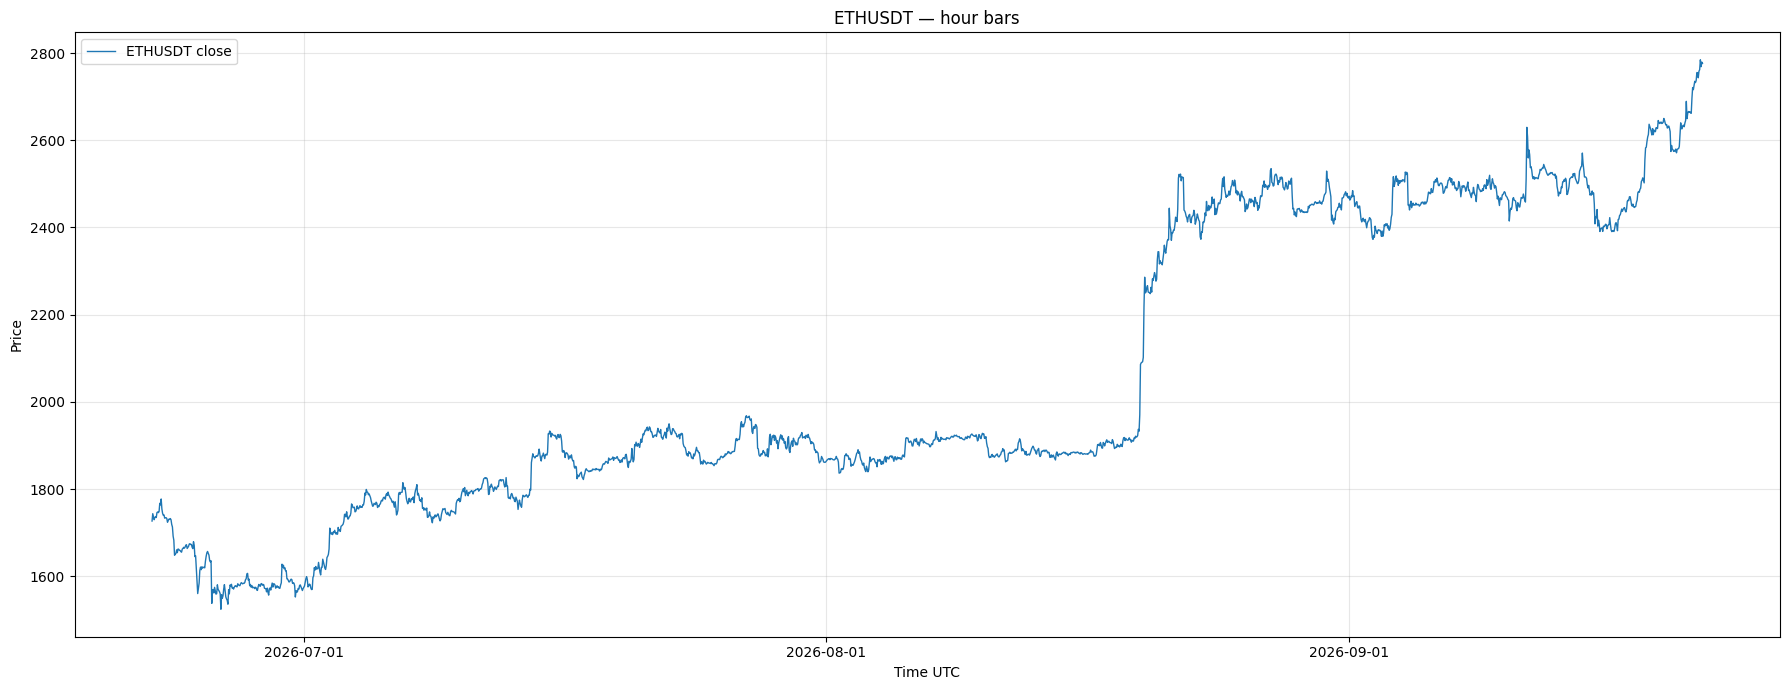

In [2]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

if "bars" not in globals() or bars.empty:
    raise RuntimeError("No bar data")

fig, ax = plt.subplots(figsize=(18, 7))

ax.plot( bars["open_time"], bars["close"], linewidth=1, label=f"{SYMBOL} close",)

ax.set_title(f"{SYMBOL} — hour bars")
ax.set_xlabel("Time UTC")
ax.set_ylabel("Price")
ax.grid(True, alpha=0.3)
ax.legend()

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d", tz=bars["open_time"].dt.tz))

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [3]:
import random
import pandas as pd
import matplotlib.pyplot as plt

def choose_daily_intervals(
    bars: pd.DataFrame,
    interval_hours: int,
    seed: int | None = None,
) -> list[dict]:
    """
    Pickes up one random interval within the day. The interval doesn't cross the day.
    Returns: start_time, end_time, start_price, end_price, price_diff
    """

    if interval_hours < 1:
        raise ValueError("interval_hours must be >= 1")

    data = bars.copy()
    data["open_time"] = pd.to_datetime(data["open_time"], utc=True)
    data = data.sort_values("open_time").reset_index(drop=True)
    data["day"] = data["open_time"].dt.date

    rng = random.Random(seed)
    result = []

    for day, day_bars in data.groupby("day", sort=True):
        day_bars = day_bars.reset_index(drop=True)

        # Possible starts: interval fully fits the day
        valid_starts = range(len(day_bars) - interval_hours + 1)

        candidates = []

        for start_idx in valid_starts:
            window = day_bars.iloc[start_idx:start_idx + interval_hours]

            # Confirm that interval lasts for 1 hour
            expected = pd.date_range(
                start=window.iloc[0]["open_time"],
                periods=interval_hours,
                freq="1h",
                tz="UTC",
            )

            if window["open_time"].reset_index(drop=True).equals(
                pd.Series(expected, name="open_time")
            ):
                candidates.append(window)

        if not candidates:
            raise ValueError(
                f"The dat {day} doesn't have an interval with length {interval_hours} h."
            )

        window = rng.choice(candidates)

        start_price = float(window.iloc[0]["open"])
        end_price = float(window.iloc[-1]["close"])

        result.append({
            "start_time": window.iloc[0]["open_time"],
            "end_time": window.iloc[-1]["open_time"],
            "start_price": start_price,
            "end_price": end_price,
            "price_diff": end_price - start_price,
        })

    return result

def plot_chart(my_intervals):
    if not my_intervals:
        raise ValueError("The intervals list is empty")
    
    interval_df = pd.DataFrame(my_intervals).sort_values("end_time")
    
    fig, ax1 = plt.subplots(figsize=(18, 7))
    
    # Main price chart
    ax1.plot(
        bars["open_time"],
        bars["close"],
        color="steelblue",
        linewidth=1,
        label="Close price",
    )
    ax1.set_xlabel("Date")
    ax1.set_ylabel("Price", color="steelblue")
    ax1.tick_params(axis="y", labelcolor="steelblue")
    ax1.grid(True, alpha=0.25)
    
    # Cumulative result
    ax2 = ax1.twinx()
    ax2.plot(
        interval_df["end_time"],
        interval_df["cumulative_price_diff"],
        color="darkorange",
        linewidth=2,
        marker="o",
        markersize=3,
        label="Cumulative price diff",
    )
    ax2.set_ylabel("Cumulative price_diff", color="darkorange")
    ax2.tick_params(axis="y", labelcolor="darkorange")
    
    ax1.set_title(f"{SYMBOL}: price and cumulative price_diff")
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

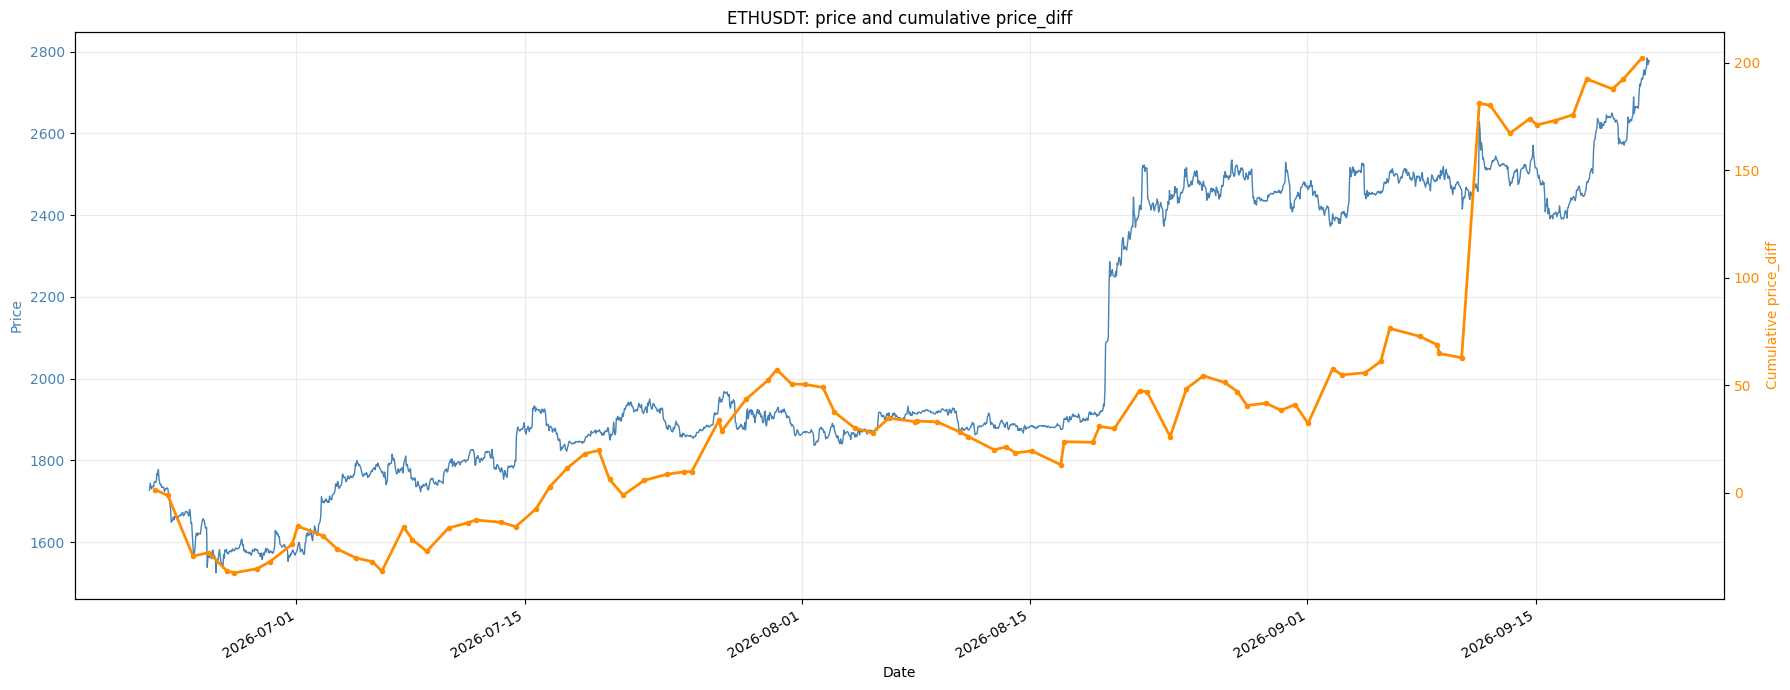

In [4]:
intervals = choose_daily_intervals(
    bars,
    interval_hours=1,
    seed=73,
)

len(intervals), intervals[:5]

running_total = 0.0

for item in intervals:
    running_total += item["price_diff"]
    item["cumulative_price_diff"] = running_total

len(intervals), intervals[:5]

plot_chart(intervals)

In [ ]:
from tqdm.auto import tqdm

N = 200
interval_hours = 1

simulations = []

for seed in tqdm(range(N), desc="Running simulations", unit="sim"):
    intervals = choose_daily_intervals(
        bars,
        interval_hours=interval_hours,
        seed=seed,
    )

    df = pd.DataFrame(intervals)
    df["cumulative_price_diff"] = df["price_diff"].cumsum()
    df["simulation"] = seed + 1

    simulations.append(df)

print(f"Generated {len(simulations)} simulations")

Running simulations:   0%|          | 0/200 [00:00<?, ?sim/s]

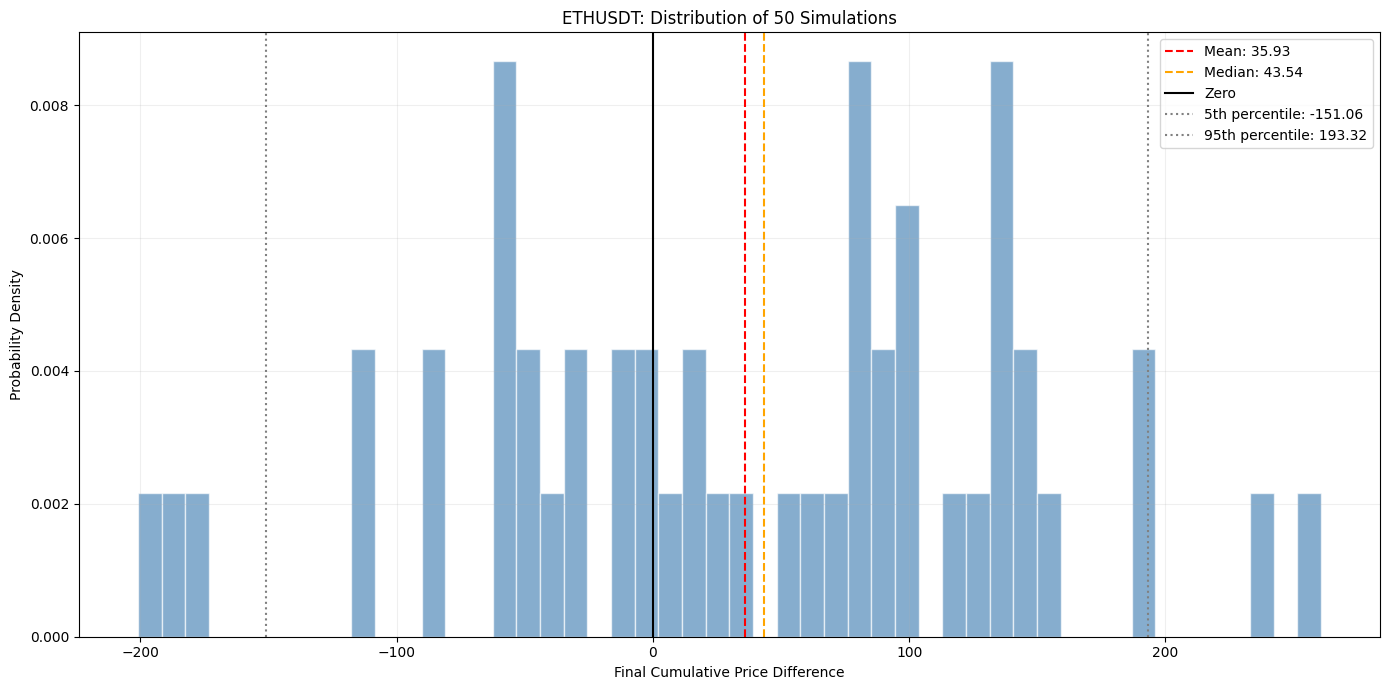

Mean:           35.93
Median:         43.54
Std deviation:  107.30
5th percentile: -151.06
95th percentile:193.32
P(Result > 0):  60.00%


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Final result of each simulation
results = np.array([
    df["cumulative_price_diff"].iloc[-1]
    for df in simulations
])

mean = results.mean()
median = np.median(results)
std = results.std(ddof=1)
p5, p95 = np.percentile(results, [5, 95])
prob_positive = np.mean(results > 0)

fig, ax = plt.subplots(figsize=(14, 7))

ax.hist(
    results,
    bins=50,
    density=True,
    alpha=0.65,
    color="steelblue",
    edgecolor="white"
)

ax.axvline(mean, color="red", linestyle="--", label=f"Mean: {mean:.2f}")
ax.axvline(median, color="orange", linestyle="--", label=f"Median: {median:.2f}")
ax.axvline(0, color="black", linestyle="-", label="Zero")
ax.axvline(p5, color="gray", linestyle=":", label=f"5th percentile: {p5:.2f}")
ax.axvline(p95, color="gray", linestyle=":", label=f"95th percentile: {p95:.2f}")

ax.set_title(f"{SYMBOL}: Distribution of {len(results)} Simulations")
ax.set_xlabel("Final Cumulative Price Difference")
ax.set_ylabel("Probability Density")

ax.grid(True, alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

print(f"Mean:           {mean:.2f}")
print(f"Median:         {median:.2f}")
print(f"Std deviation:  {std:.2f}")
print(f"5th percentile: {p5:.2f}")
print(f"95th percentile:{p95:.2f}")
print(f"P(Result > 0):  {prob_positive:.2%}")

In [11]:
import numpy as np

results = np.array([
    df["cumulative_price_diff"].iloc[-1]
    for df in simulations
])

print(f"P(Result > 0):  {np.mean(results > 0):.2%}")
print(f"P(Result < 0):  {np.mean(results < 0):.2%}")
print(f"P(Result > 100): {np.mean(results > 100):.2%}")
print(f"P(Result < -100): {np.mean(results < -100):.2%}")

P(Result > 0):  60.00%
P(Result < 0):  40.00%
P(Result > 100): 28.00%
P(Result < -100): 10.00%


In [12]:
bars.columns

Index(['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time',
       'quote_volume', 'trades', 'taker_buy_volume', 'taker_buy_quote_volume',
       'ignore'],
      dtype='object')

In [ ]:
-